# 6. Data centre powering — optimiser results

Where the numbers come from and what they mean.

The optimiser itself lives in `optimisation/dc_model.py` and friends — this notebook
imports it and does the analysis and plots, the same relationship `4.1`–`4.3` have with
`lca_helpers.py`. Nothing here reimplements any science.

**What it covers**

1. Load a solved matrix (or solve one configuration live)
2. The cost/carbon Pareto front, and the three answers on it
3. What each option actually builds
4. Where the carbon comes from — embodied against operational
5. A dispatch week, and the seasonal tank cycle
6. **The value of foresight** — the same build dispatched by the LP and by
   notebook 4.3's merit order, which brackets what a real operator would get

**Before you start.** The matrix is solved by `scripts/run_dc_scenarios.py`, not by this
notebook — 273 LPs take about 15 minutes across 8 cores and should not live in a cell.
If `optimisation_outputs/dc_runs/` is empty, run this first:

```bash
python scripts/run_dc_scenarios.py --workers 8 --points 12
```

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from optimisation import (dc_architectures as A, dc_inputs as I, dc_model as M,
                          dc_pareto as P, dc_runner, myopic, sites)

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

# A GB coordinate is the input — the Carbon Intensity region and TNUoS zone
# are derived from it. Central London, which is the region the cached grid
# series covers. Presets: sites.PRESETS.
SITE = sites.resolve(51.5074, -0.1278)
SIZE_MW, START, END = 7.31, "2025-01-01", "2025-12-29"
RUN_DIR = ROOT / "optimisation_outputs" / "dc_runs" / f"{SITE.key}_{SIZE_MW:g}MW_{START[:4]}"
print(SITE.describe())
print(RUN_DIR.name, "exists:", RUN_DIR.exists())

Westminster — CI region 13 (London), TNUoS zone 12, no offshore option, connection unconstrained
r13_51.5074_-0.1278_7.31MW_2025 exists: True


## 1. Load the solved matrix

`summary.json` per scenario is the atom; `comparison_table` flattens them to one row per
configuration per answer (min cost, min GWP, knee).

In [2]:
summaries = dc_runner.load_results(RUN_DIR)
if not summaries:
    raise SystemExit(
        f"No solved runs found in {RUN_DIR} - the folder is gitignored and "
        "regenerable. Run the Data Centre Optimiser page or "
        "`python scripts/run_dc_scenarios.py` from the repo root first, "
        "then re-run this cell."
    )
df = dc_runner.comparison_table(summaries)
print(f"{len(summaries)} configurations")

base = df[(df.architecture == "grid_only") & (df.point == "min_cost")].iloc[0]
BASE_COST, BASE_GWP = base.cost_m_GBP_per_year, base.gwp_t_per_year
print(f"baseline: £{BASE_COST:.2f} m/yr, {BASE_GWP:,.0f} t CO2e/yr, {base.gwp_g_per_kWh:.1f} g/kWh")

knee = df[df.point == "knee"].sort_values("gwp_t_per_year")
knee[["n", "label", "strategy", "cost_m_GBP_per_year", "gwp_t_per_year",
      "gwp_g_per_kWh", "degenerate"]].round(2)

21 configurations
baseline: £6.60 m/yr, 16,014 t CO2e/yr, 250.1 g/kWh


,n,label,strategy,cost_m_GBP_per_year,gwp_t_per_year,gwp_g_per_kWh,degenerate
60,21,Everything available — control,free,6.26,3616.92,56.48,False
6,3,Grid + renewables + battery,free,6.26,3616.92,56.48,False
33,12,"Renewables + H2 (AE), islanded",baseload,14.13,4971.14,77.63,False
27,10,"Renewables + H2 (PEM), islanded",baseload,14.34,4978.06,77.74,False
30,11,"Renewables + H2 (PEM), islanded",flexible,13.76,5123.14,80.00,False
36,13,"Renewables + H2 (AE), islanded",flexible,13.48,5169.27,80.72,False
42,15,"Renewables + H2 (SOEC), islanded",flexible,14.13,5480.02,85.58,False
39,14,"Renewables + H2 (SOEC), islanded",baseload,14.48,5604.09,87.52,False
48,17,Grid + bought H2 (blue),free,9.68,13778.80,215.17,False
3,2,Grid + battery,free,8.79,14210.81,221.92,False


### How many options actually trade cost against carbon?

A **degenerate** front means minimum cost and minimum emissions picked the same system —
there is no trade-off to make. For the grid + hydrogen rows this means something specific:
the optimiser declined to build a hydrogen chain at all, so the answer collapses onto the
grid-only baseline.

In [3]:
deg = df[(df.point == "knee")]
print(f"{deg.degenerate.sum()} of {len(deg)} configurations are degenerate\n")
for _, r in deg[deg.degenerate].iterrows():
    print(f"  {r.n:>2}  {r.label} · {r.strategy}")

10 of 21 configurations are degenerate

   1  Grid only · free
   4  Grid + H2 (PEM) · baseload
   5  Grid + H2 (PEM) · flexible
   6  Grid + H2 (AE) · baseload
   7  Grid + H2 (AE) · flexible
   8  Grid + H2 (SOEC) · baseload
   9  Grid + H2 (SOEC) · flexible
  16  Grid + bought H2 (grey) · free
  19  Grid + bought H2 (green) · free
  20  Grid + H2 (PEM) — control · free


## 2. Where every option lands

Down and left is better on both axes. The dashed lines are the grid-only baseline, so
anything in the lower-left quadrant beats doing nothing on **both** cost and carbon.

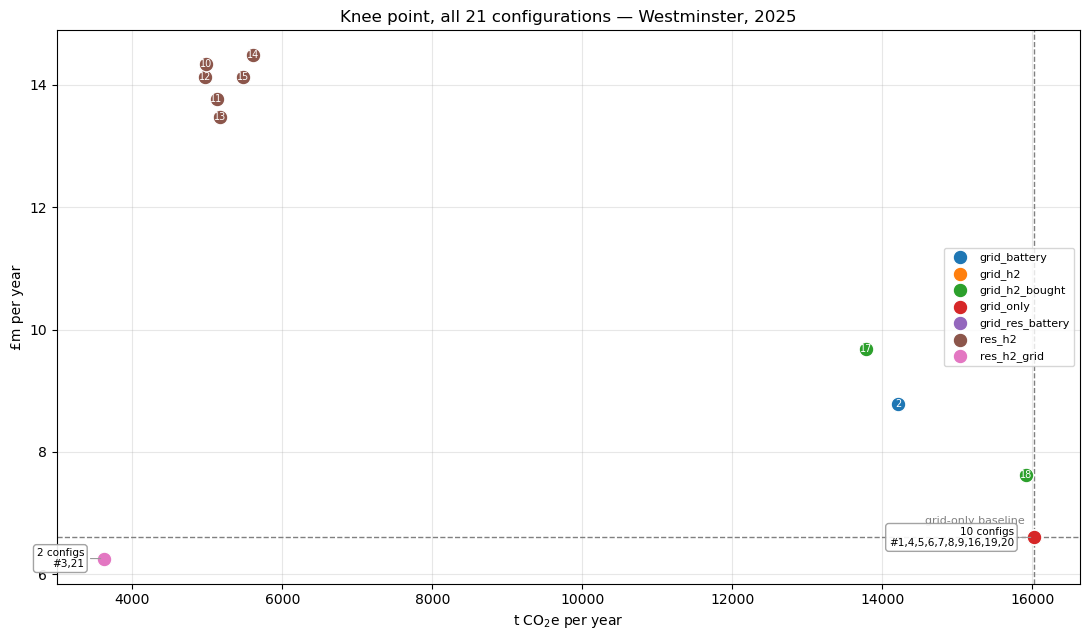

In [4]:
# Configurations that land on the same point would otherwise hide each other —
# and here that overlap IS the finding, so it gets labelled rather than jittered.
knee = knee.copy()
knee["_cell"] = (knee.gwp_t_per_year.round(-1).astype(int).astype(str) + "_"
                 + knee.cost_m_GBP_per_year.round(2).astype(str))
groups = knee.groupby("_cell")

fig, ax = plt.subplots(figsize=(11, 6.5))
colours = {a: c for a, c in zip(sorted(knee.architecture.unique()), plt.cm.tab10.colors)}
for arch, g in knee.groupby("architecture"):
    ax.scatter(g.gwp_t_per_year, g.cost_m_GBP_per_year, s=110,
               label=arch, color=colours[arch], zorder=3, edgecolor="white", lw=0.8)

for _, g in groups:
    x, y = g.gwp_t_per_year.iloc[0], g.cost_m_GBP_per_year.iloc[0]
    nums = ",".join(str(int(n)) for n in sorted(g.n))
    if len(g) == 1:
        ax.annotate(nums, (x, y), fontsize=7, ha="center", va="center",
                    color="white", zorder=5)
    else:
        ax.annotate(f"{len(g)} configs\n#{nums}", (x, y), fontsize=7.5,
                    ha="right", va="center", xytext=(-14, 0),
                    textcoords="offset points", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.6", alpha=0.9),
                    arrowprops=dict(arrowstyle="-", color="0.6", lw=0.8))

ax.axvline(BASE_GWP, ls="--", c="grey", lw=1)
ax.axhline(BASE_COST, ls="--", c="grey", lw=1)
ax.annotate("grid-only baseline", (BASE_GWP, BASE_COST), fontsize=8, color="grey",
            xytext=(-6, 10), textcoords="offset points", ha="right")
ax.set_xlabel("t CO$_2$e per year"); ax.set_ylabel("£m per year")
ax.set_title(f"Knee point, all {len(knee)} configurations — {SITE.name}, {START[:4]}")
ax.legend(fontsize=8, loc="center right")
plt.tight_layout()

## 3. The Pareto front for one configuration

Pick a non-degenerate one to see an actual trade-off curve. Each point is a separate LP
solve: *the cheapest system that achieves this carbon level*. The three marked answers all
come from the one sweep.

The **knee** is the default reading of "the intersection of the two" — the point closest to
the utopia corner on the normalised front, which needs no carbon price. The
**carbon-price** point uses the FES 2025 GB figure (£78.96/tCO₂) that `h2_prices.py`
already loads, rather than an invented λ.

Grid + renewables + battery · free — 13 points, degenerate=False


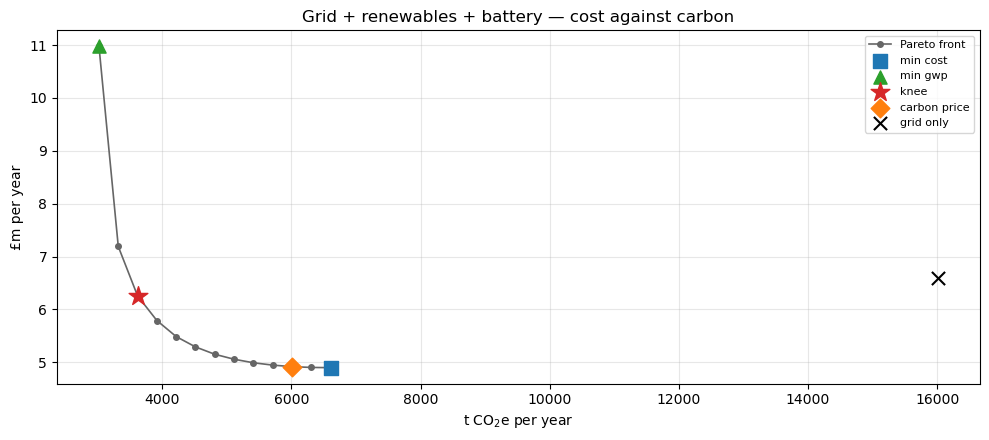

In [5]:
CHOICE = "03_grid_res_battery_free"      # change me

s = next(x for x in summaries if x["key"] == CHOICE)
front = pd.read_parquet(RUN_DIR / CHOICE / "pareto.parquet")
print(f"{s['label']} · {s['strategy']} — {len(front)} points, "
      f"degenerate={s['degenerate']}")

fig, ax = plt.subplots()
ax.plot(front.gwp_kgco2e_per_year / 1e3, front.cost_GBP_per_year / 1e6,
        "-o", color="0.4", ms=4, lw=1.2, label="Pareto front", zorder=2)
for name, colour, marker in (("min_cost", "tab:blue", "s"),
                             ("min_gwp", "tab:green", "^"),
                             ("knee", "tab:red", "*"),
                             ("carbon_price", "tab:orange", "D")):
    p = s[name]
    ax.scatter(p["gwp_kgco2e_per_year"] / 1e3, p["cost_GBP_per_year"] / 1e6,
               s=200 if name == "knee" else 90, c=colour, marker=marker,
               zorder=4, label=name.replace("_", " "))
ax.scatter(BASE_GWP, BASE_COST, marker="x", c="k", s=90, zorder=4, label="grid only")
ax.set_xlabel("t CO$_2$e per year"); ax.set_ylabel("£m per year")
ax.set_title(f"{s['label']} — cost against carbon")
ax.legend(fontsize=8)
plt.tight_layout()

## 4. What each option builds

The mix is the answer to the actual question — *what infrastructure do I install?*
Capacities that stay at zero are dropped.

,min_cost,knee,min_gwp
asset,,,
Wind MW,12.48,27.73,59.88
Solar MWp,13.90,11.27,0.00
Battery MW,3.02,5.26,9.49
Battery MWh,19.01,49.40,56.67
Grid MW,5.98,4.64,16.68


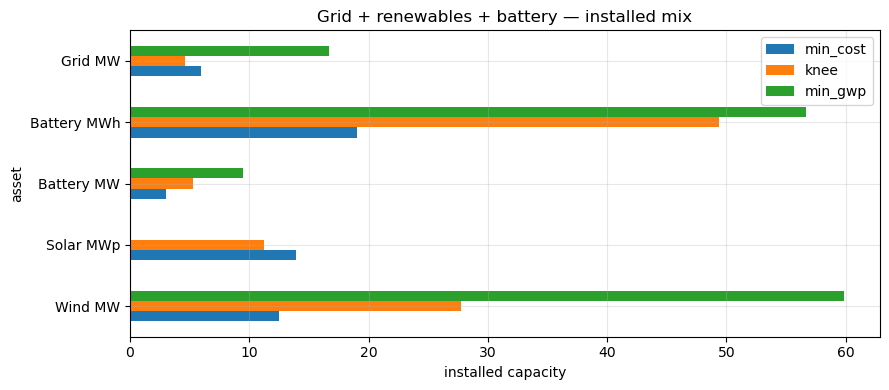

In [6]:
CAPS = [("cap_wind", "Wind MW"), ("cap_offshore", "Offshore MW"), ("cap_solar", "Solar MWp"),
        ("cap_batt_p", "Battery MW"), ("cap_batt_e", "Battery MWh"),
        ("cap_ely", "Electrolyser MW"), ("cap_tank", "H2 tank t"),
        ("cap_fc", "Fuel cell MW"), ("cap_grid", "Grid MW")]

mix = pd.DataFrame([
    {"asset": lab,
     **{p: (s[p][k] / 1000 if k == "cap_tank" else s[p][k])
        for p in ("min_cost", "knee", "min_gwp")}}
    for k, lab in CAPS])
mix = mix[(mix[["min_cost", "knee", "min_gwp"]].abs() > 1e-6).any(axis=1)].set_index("asset")

ax = mix.plot.barh(figsize=(9, 4))
ax.set_xlabel("installed capacity"); ax.set_title(f"{s['label']} — installed mix")
plt.tight_layout()
mix.round(2)

## 5. Where the carbon actually comes from

The split that decides whether an option is genuinely better or has just moved its burden
upstream. **Embodied** is what we put in the ground; **operational** is what we import and
burn; **facility** is the data centre building itself, which is identical across every
option and so never changes a ranking — reported separately for exactly that reason.

This re-solves the chosen configuration at its knee, because the contribution split needs
the full solution and only the summary is cached.

In [7]:
base_series, meta = I.build_series(SITE, START, END, SIZE_MW, pue=1.0)
series = I.resample(base_series, 1.0)
tech = I.build_tech(SITE, meta, ely_tech=s["ely_tech"] or "PEM operation",
                    h2_colour=s["h2_colour"], size_mw_it=SIZE_MW, pue=1.0)
assets = A.architecture(s["architecture"], offshore=SITE.offshore_wind)
if s["h2_colour"] is None and assets.buy_h2:
    import dataclasses; assets = dataclasses.replace(assets, buy_h2=False)

m, V, obj = M.build_model(series, assets, tech, objective="cost",
                          gwp_limit=s["knee"]["gwp_kgco2e_per_year"],
                          ely_strategy=s["strategy"])
M.solve(m)
con = M.contributions(V, obj, series, tech, assets)
print(f"total {con['totals']['gwp_kgco2e_per_year']/1000:,.0f} t CO2e/yr")

total 6,605 t CO2e/yr


group
embodied       18.3
facility       12.7
operational    69.0 
(% of total)


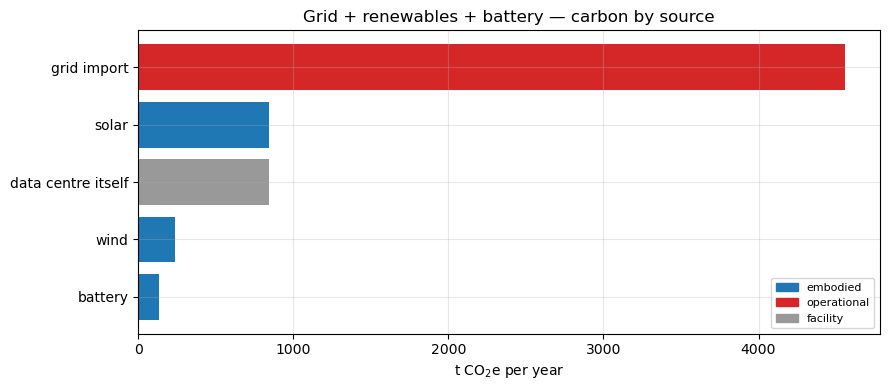

In [8]:
groups = {"embodied": con["gwp_embodied"], "operational": con["gwp_operational"],
          "facility": con["gwp_facility"]}
rows = [{"group": g, "source": k, "t_per_year": v / 1000}
        for g, d in groups.items() for k, v in d.items() if abs(v) > 1]
cdf = pd.DataFrame(rows).sort_values("t_per_year", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
gc = {"embodied": "tab:blue", "operational": "tab:red", "facility": "0.6"}
ax.barh(cdf.source, cdf.t_per_year, color=[gc[g] for g in cdf.group])
ax.set_xlabel("t CO$_2$e per year"); ax.invert_yaxis()
ax.set_title(f"{s['label']} — carbon by source")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in gc.values()]
ax.legend(handles, gc.keys(), fontsize=8)
plt.tight_layout()

summary = cdf.groupby("group").t_per_year.sum()
print((summary / summary.sum() * 100).round(1).to_string(), "\n(% of total)")

## 6. A dispatch week, and the seasonal tank

The top panel is what the LP decided to run hour by hour. The bottom is the whole year's
storage state — and it is the argument for solving sizing and dispatch *together*: a tank
that fills in spring and drains in autumn cannot be sized before its dispatch is known.

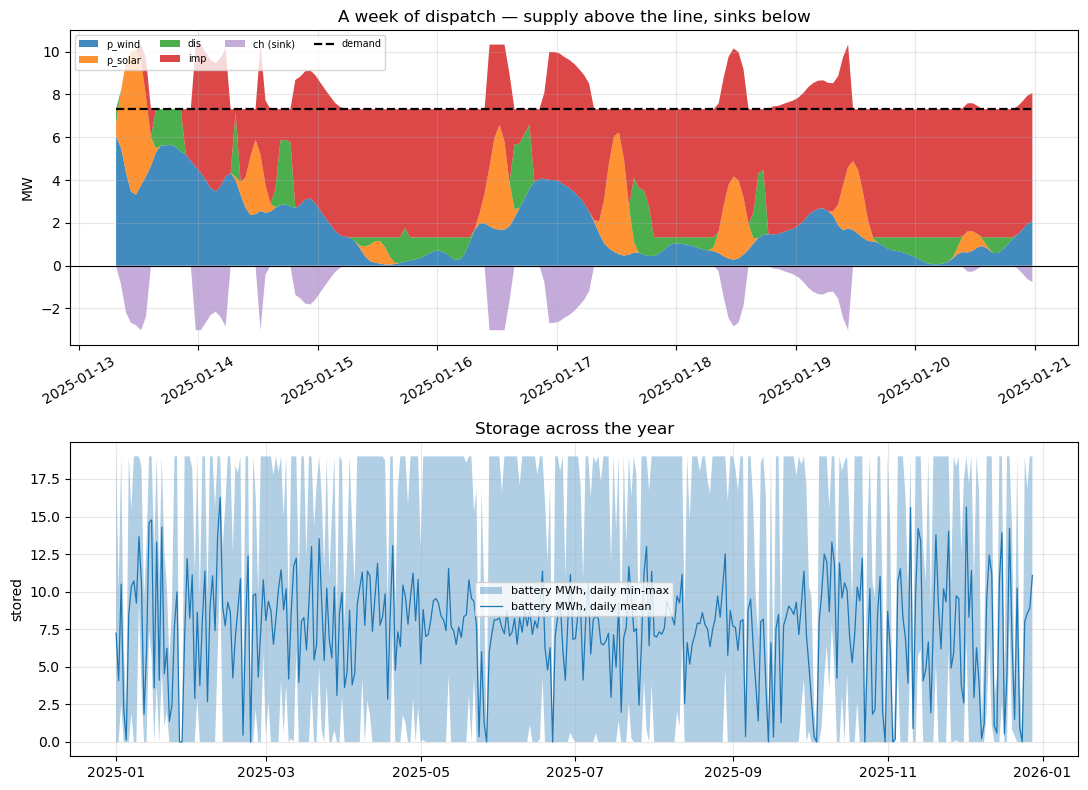

In [9]:
disp = M.dispatch_frame(V, series)
week = disp.loc["2025-01-13":"2025-01-20"]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 8))

# Supply above the line, sinks below it. Without splitting them the stack rises
# above demand whenever the battery is charging, which reads as an error.
supply = [c for c in ("p_wind", "p_offshore", "p_solar", "dis", "p_fc", "imp", "unserved")
          if week[c].abs().sum() > 1e-6]
sinks = [c for c in ("ch", "p_ely", "exp", "curtailed") if week[c].abs().sum() > 1e-6]
a1.stackplot(week.index, *[week[c] for c in supply], labels=supply, alpha=0.85)
if sinks:
    a1.stackplot(week.index, *[-week[c] for c in sinks],
                 labels=[f"{c} (sink)" for c in sinks], alpha=0.55)
a1.plot(week.index, week.demand, "k--", lw=1.6, label="demand")
a1.axhline(0, color="k", lw=0.8)
a1.set_ylabel("MW"); a1.legend(fontsize=7, ncol=4, loc="upper left")
a1.set_title("A week of dispatch — supply above the line, sinks below")
a1.tick_params(axis="x", rotation=30)

# Annual storage: a battery cycling daily is unreadable at 8,760 points, so show
# the daily envelope instead. A hydrogen tank genuinely is seasonal and is drawn
# as a line, which is the whole argument for solving sizing and dispatch together.
plotted = False
if disp.soc.abs().sum() > 1e-6:
    d = disp.soc.resample("1D")
    a2.fill_between(d.min().index, d.min(), d.max(), alpha=0.35,
                    label="battery MWh, daily min-max")
    a2.plot(d.mean().index, d.mean(), lw=0.9, label="battery MWh, daily mean")
    plotted = True
if disp.tank.abs().sum() > 1e-6:
    a2.plot(disp.index, disp.tank / 1000, lw=1.1, color="tab:green",
            label="H$_2$ tank, t")
    plotted = True
if not plotted:
    a2.text(0.5, 0.5, "this configuration builds no storage",
            ha="center", va="center", transform=a2.transAxes, color="0.4")
a2.set_ylabel("stored"); a2.legend(fontsize=8)
a2.set_title("Storage across the year")
plt.tight_layout()

## 7. The value of foresight

**Read this before quoting any number above.**

Every LP result assumes the whole year is known in advance — it electrolyses in March
surplus *because* it knows a November lull is coming. No operator has that forecast, so the
LP is an **upper bound** on what a build can achieve, not a prediction of what it will.

`optimisation/myopic.py` is the opposite bound: the same installed capacities, dispatched
by the fixed merit order from `4.3.wind_h2_storage_system.ipynb`, which sees only the
current step. Truth is bracketed between them.

In [10]:
caps = {k: float(V[k].solution) for k, _ in CAPS}
caps["cap_grid"] = float(V["cap_grid"].solution)
b = myopic.bracket(series, tech, caps, M.totals(obj), V)
b.round(3)

,dispatch,cost_m_GBP_per_year,gwp_t_per_year,unserved_MWh_per_year,unserved_pct,cost_excl_VoLL_m
0,LP (perfect foresight),4.898,6605.263,0.000,0.000,4.898
1,merit order (no foresight),34.013,6600.645,290.566,0.454,4.956


### What the bracket actually says

Excluding the VoLL penalty the two dispatches cost almost the same — myopic dispatch is
nearly as good at *running* the system. The gap is that it **fails to serve load** on a
build the LP sized to have none, because the LP chose the grid connection knowing exactly
when the battery would be needed.

So the finding is not "foresight is worth £X". It is that **an LP-sized build is not robust
to imperfect foresight**. If you want a build that survives real operation, either size the
grid connection above what the LP asks for, or re-run with a non-zero `--unserved`
allowance and read the cost of the headroom.

This is the honest limit of the whole study, and it is listed as untested in
`optimisation/VALIDATION.md` precisely because it needs judgement rather than a threshold.

In [11]:
lost = b.unserved_MWh_per_year.iloc[1]
mwh = con["demand_MWh_per_year"]
print(f"merit order leaves {lost:,.0f} MWh unserved ({100*lost/mwh:.2f} % of demand)")
print(f"cost excluding VoLL: LP £{b.cost_excl_VoLL_m.iloc[0]:.2f} m, "
      f"merit order £{b.cost_excl_VoLL_m.iloc[1]:.2f} m")
print(f"\ngrid connection the LP chose: {caps['cap_grid']:.2f} MW "
      f"against {SIZE_MW:.2f} MW of demand")

merit order leaves 291 MWh unserved (0.45 % of demand)
cost excluding VoLL: LP £4.90 m, merit order £4.96 m

grid connection the LP chose: 5.98 MW against 7.31 MW of demand


## Caveats that travel with every number here

* **One site, one year.** Only London has cached grid data. Scotland and East England need
  `3.1.custom_grid_carbon_intensity_api.ipynb` re-run for their regions —
  `sites.require_grid_region()` refuses to substitute London's intensities. Given TNUoS
  demand tariffs alone swing £0/kW (Scotland, floored) to £10.12/kW (South West), the
  locational result is probably the headline and it is not computed yet.
* **Hydrogen costs are assumed.** Fuel cell and vessel capex have no UK source and spreads
  of 4.5× and 2×. The carbon side of the same architectures is fully sourced — so rank
  hydrogen on carbon with confidence and on cost only with the caveat. See
  `optimisation/DATA_GAPS.md`.
* **The battery is locked** in the core hydrogen rows, deliberately, so each row measures
  one technology. It is one line to reverse and is on the sensitivity list.
* **No unit commitment.** The LP may run an electrolyser at 1 % of rating.
* **Perfect foresight**, per section 7.